# 02 - C-MAPSS RUL modelling review

This notebook reviews the NASA C-MAPSS FD001 remaining-useful-life models: a Ridge
last-cycle baseline, an XGBoost window-summary model and a PyTorch LSTM. It reads
the saved metrics and watchlist; it does not retrain.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
print("Repository root:", ROOT)


Repository root: D:\project learning


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from flightops.config import load_config

cfg = load_config()
metrics = json.loads((cfg.path("paths.metrics") / "rul_metrics.json").read_text())
watch = pd.read_csv(cfg.path("paths.metrics") / "rul_watchlist.csv")
cost = pd.read_csv(cfg.path("paths.metrics") / "rul_alert_cost.csv")
cmapss = pd.read_parquet(cfg.path("data.rul.parquet"))
print("Test engines:", len(watch))
print("Models:", ", ".join(metrics["models"]))


Test engines: 100
Models: ridge_last_cycle, xgboost_window, lstm


## 1. Model comparison

In [3]:
rows = []
for name, m in metrics["models"].items():
    rows.append({"model": name, **{k: m[k] for k in ["rmse", "mae", "r2", "nasa_score_mean", "late_prediction_rate", "p90_abs_error"]}})
table = pd.DataFrame(rows)
table.style.format({"rmse": "{:.2f}", "mae": "{:.2f}", "r2": "{:.3f}", "nasa_score_mean": "{:.2f}", "late_prediction_rate": "{:.0%}", "p90_abs_error": "{:.1f}"})


,model,rmse,mae,r2,nasa_score_mean,late_prediction_rate,p90_abs_error
0,ridge_last_cycle,21.36,17.13,0.736,10.69,56%,35.5
1,xgboost_window,14.00,10.45,0.886,2.86,61%,23.5
2,lstm,15.37,11.55,0.863,3.60,46%,25.3


In [4]:
print(f"Conformal 90% interval: +/-{metrics['conformal']['q_cycles']:.1f} cycles")
print(f"Empirical test coverage: {metrics['conformal']['test_coverage']:.1%}")
print(f"Selected alert threshold: {metrics['alerts']['selected_threshold_cycles']} cycles")
print(f"Cost-optimal threshold: {metrics['alerts']['cost_optimal_threshold_cycles']} cycles")
print(f"Selected precision/recall: {metrics['alerts']['selected']['precision']:.1%} / {metrics['alerts']['selected']['recall']:.1%}")


Conformal 90% interval: +/-22.6 cycles
Empirical test coverage: 83.0%
Selected alert threshold: 20 cycles
Cost-optimal threshold: 19 cycles
Selected precision/recall: 88.2% / 93.8%


## 2. Prediction quality and asymmetry

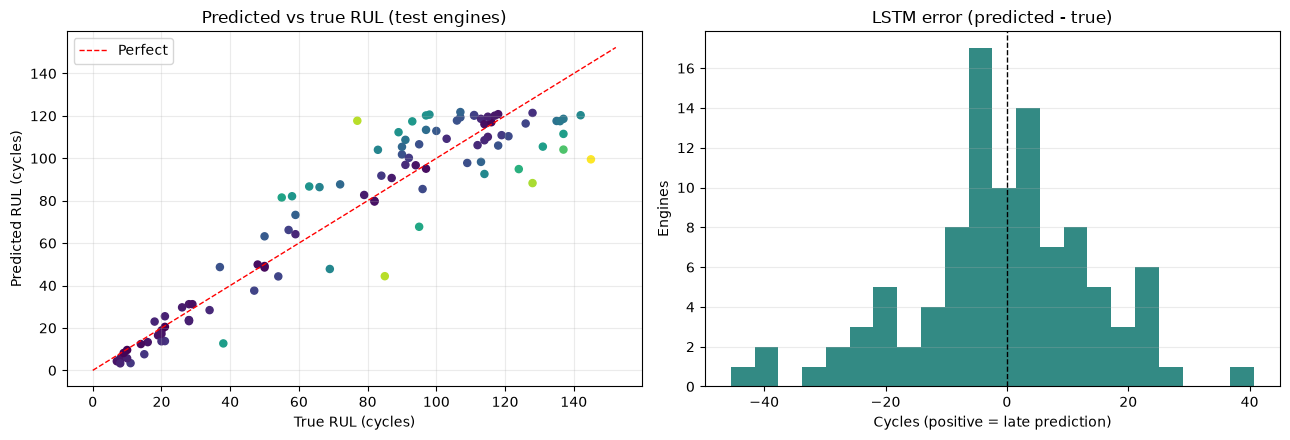

Late-prediction rate: 46.0%; mean error -0.74 cycles


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(watch["true_rul_cycles"], watch["predicted_rul_cycles"], c=np.abs(watch["predicted_rul_cycles"] - watch["true_rul_cycles"]), cmap="viridis", s=26)
lim = max(watch["true_rul_cycles"].max(), watch["predicted_rul_cycles"].max()) * 1.05
axes[0].plot([0, lim], [0, lim], "r--", linewidth=1, label="Perfect")
axes[0].set(title="Predicted vs true RUL (test engines)", xlabel="True RUL (cycles)", ylabel="Predicted RUL (cycles)")
axes[0].legend()
axes[0].grid(alpha=0.25)

errors = watch["predicted_rul_cycles"] - watch["true_rul_cycles"]
axes[1].hist(errors, bins=22, color="#0f766e", alpha=0.85)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(title="LSTM error (predicted - true)", xlabel="Cycles (positive = late prediction)", ylabel="Engines")
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Late-prediction rate: {(errors > 0).mean():.1%}; mean error {errors.mean():+.2f} cycles")


## 3. Alert threshold economics

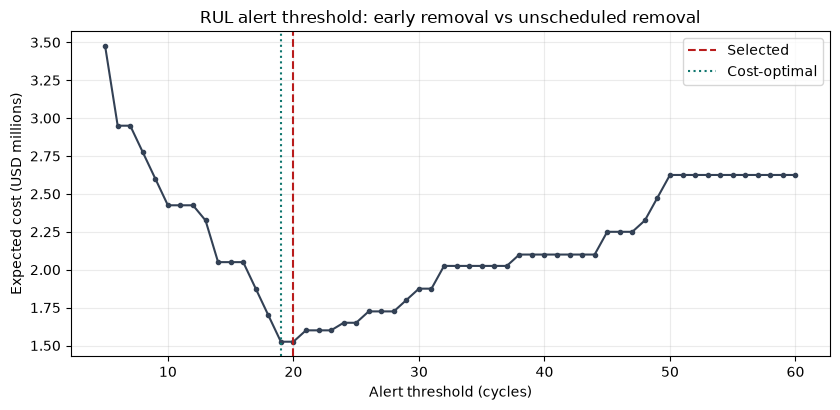

Cost at selected threshold: $1.52M
No-alert benchmark: $4.00M
Remove-all-early benchmark: $7.50M


In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(cost["threshold_cycles"], cost["total_cost_usd"] / 1e6, color="#334155", marker="o", markersize=3)
ax.axvline(metrics["alerts"]["selected_threshold_cycles"], color="#b91c1c", linestyle="--", label="Selected")
ax.axvline(metrics["alerts"]["cost_optimal_threshold_cycles"], color="#0f766e", linestyle=":", label="Cost-optimal")
ax.set(title="RUL alert threshold: early removal vs unscheduled removal", xlabel="Alert threshold (cycles)", ylabel="Expected cost (USD millions)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Cost at selected threshold: ${metrics['alerts']['selected']['total_cost_usd']/1e6:.2f}M")
print(f"No-alert benchmark: ${metrics['alerts']['benchmark_no_alert_cost_usd']/1e6:.2f}M")
print(f"Remove-all-early benchmark: ${metrics['alerts']['benchmark_remove_all_early_cost_usd']/1e6:.2f}M")


## 4. Watchlist and degradation trajectories

In [7]:
tiers = watch["risk_tier"].value_counts()
print(tiers.to_string())
watch.sort_values("predicted_rul_cycles").head(12)[["unit", "predicted_rul_cycles", "prediction_low", "prediction_high", "true_rul_cycles", "risk_tier"]]


risk_tier
Serviceable                   72
Watch - plan next visit       11
Critical - remove now          9
High - schedule shop visit     8


,unit,predicted_rul_cycles,prediction_low,prediction_high,true_rul_cycles,risk_tier
80,81,3.3,0.0,25.9,8.0,Critical - remove now
34,35,3.4,0.0,26.0,11.0,Critical - remove now
33,34,4.3,0.0,26.9,7.0,Critical - remove now
67,68,5.2,0.0,27.8,8.0,Critical - remove now
30,31,5.6,0.0,28.1,8.0,Critical - remove now
75,76,5.7,0.0,28.2,10.0,Critical - remove now
55,56,7.6,0.0,30.2,15.0,Critical - remove now
81,82,8.2,0.0,30.7,9.0,Critical - remove now
41,42,9.6,0.0,32.2,10.0,Critical - remove now
65,66,12.4,0.0,35.0,14.0,High - schedule shop visit


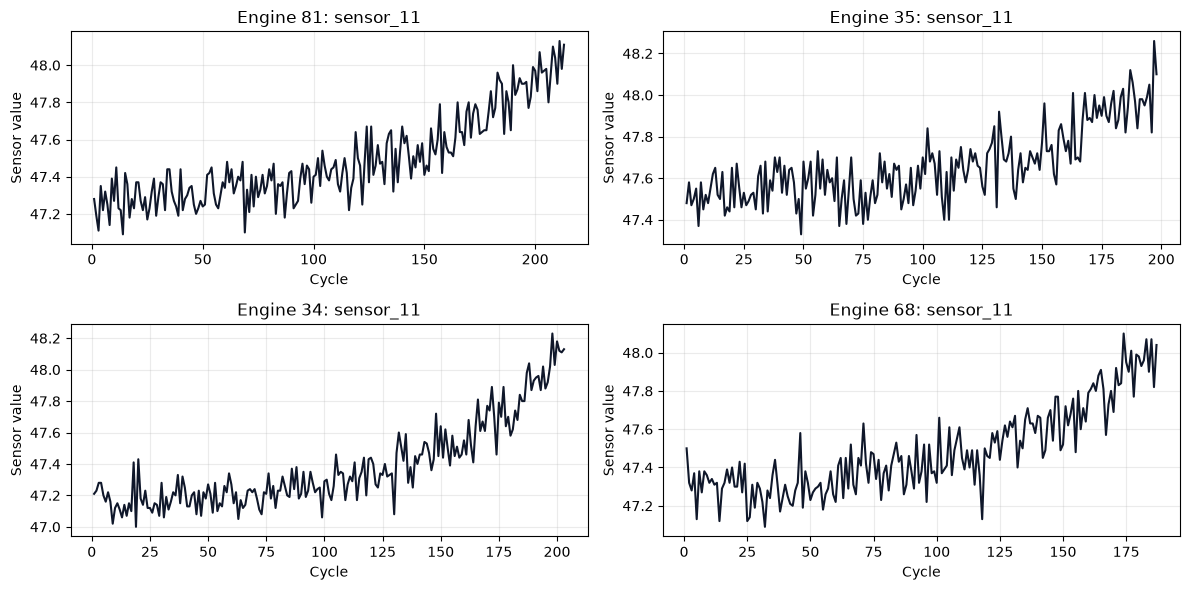

In [8]:
units = watch.sort_values("predicted_rul_cycles").head(4)["unit"].astype(int).tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=False)
for ax, unit in zip(axes.ravel(), units):
    frame = cmapss[(cmapss["split"] == "test") & (cmapss["unit"] == unit)]
    ax.plot(frame["cycle"], frame["sensor_11"], color="#0f172a")
    ax.set(title=f"Engine {unit}: sensor_11", xlabel="Cycle", ylabel="Sensor value")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 5. Limitations

- C-MAPSS is simulated turbofan degradation, not a fleet feed.
- The event is an RUL threshold, not a physical failure; cost figures are planning
  assumptions.
- The model is a decision aid. In service it must be combined with borescope, oil
  analysis and OEM limits, and signed off by a licensed engineer.
